In [1]:
import sys
sys.path.append('..')
from setup import *
from Tasks import cycling
from clustering import fit_gmm

...check complete...


In [32]:
model, model_params, task_params, training_params = load_rnn("../saved_models/resampled_populations_model")
cycles = Task.load_task("Cycling", task_params)
inputs = cycles.generate_inputs(NUM_ANGLES)
mf_model, *_ = load_rnn("../saved_models/mf_pop_dyn_chols_no_In")
mf_rates, _ = run_rnn(mf_model, inputs)


resampled = resample(mf_model, 1000, pops=None)
losses = train_rnn(resampled, cycles, training_params)



(8, 1000)
epoch 101 / 10000	time=21.08094s	task_loss=0.009766397532075644
Done: training took 21.1 sec.


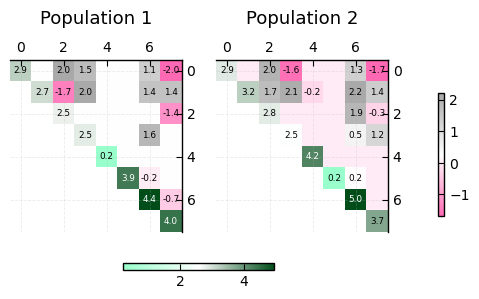

In [19]:
from clustering import fit_gmm
conn_vecs = get_model_conn_vecs(resampled)
labels, gmm = fit_gmm(conn_vecs.T, n_components=2)
covs = get_overlap_matrix_all_params(conn_vecs, pops=labels)
lower_triangular_heatmap(covs, put_text=True)
#plt.savefig("../Figures/Figures_2/covariance.png")
plt.show()


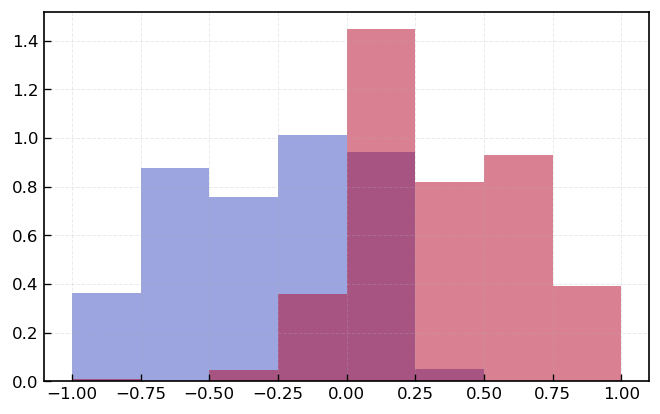

In [33]:
inputs = cycles.generate_inputs(2)
rates, _ = run_rnn(resampled, inputs)
G = phiPrime(rates)
Gcond1 = G[0,...]
Gcond2 = G[-1,...]
binwidth = .25
bins = np.arange(-1.0, 1.0+binwidth, binwidth)
with plotstyle.context("inputs", 2):
        plt.hist(
                (Gcond1[:,labels.astype(bool)].mean(axis=0)
                - Gcond2[:, labels.astype(bool)].mean(axis=0)
                ), 
                alpha=.5,
                density=True,
                bins=bins
                )
        plt.hist(
                (Gcond1[:,~labels.astype(bool)].mean(axis=0) 
                - Gcond2[:, ~labels.astype(bool)].mean(axis=0)
                ),
                alpha=.5,
                density=True,
                bins=bins
                )
plt.show()


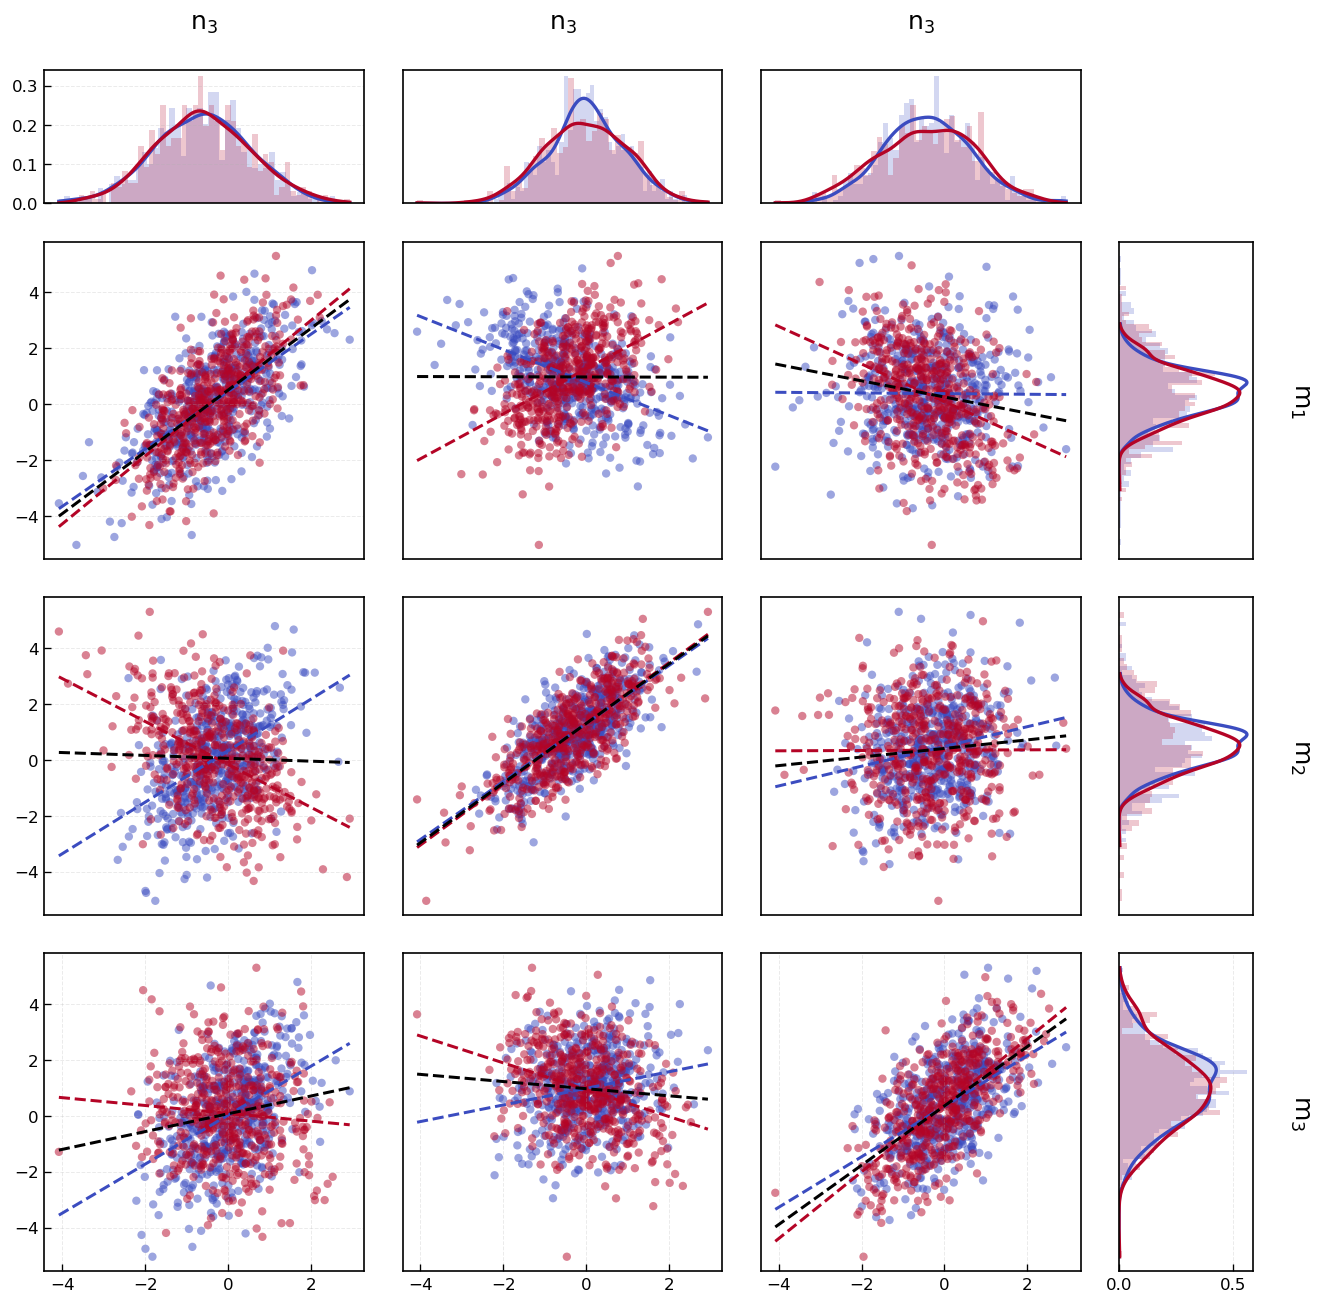

In [23]:
with plotstyle.context("inputs", NUM_ANGLES):
    connectivity_scatter_from_idxs(model, range(3), range(3,6), pops=labels)
plt.show()
# plt.savefig("../Figures/Figures_2/scatter.png")

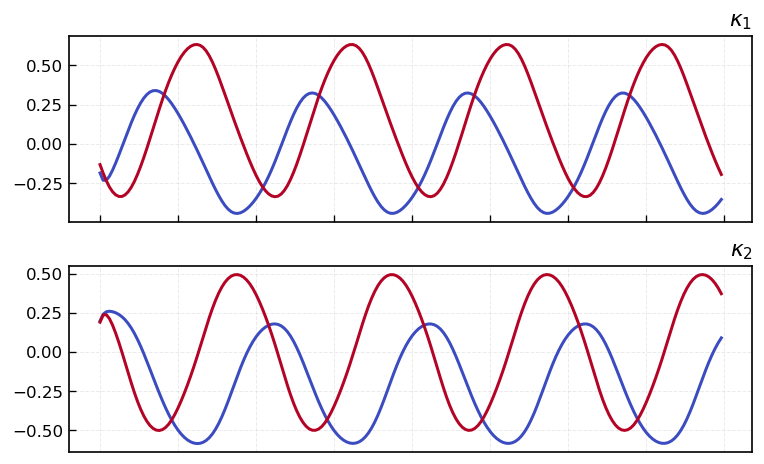

In [24]:
rates, out = run_rnn(model, inputs)
m = model.rnn.m.detach().numpy()
ks = proj_(m.T, rates)
with plotstyle.context("inputs", 2):
    fig, axs = plt.subplots(2,1, sharex=True)
    for i in [0,-1]:
        for j in range(2):
            axs[j].plot(ks[i,j,:])
            axs[j].set_title(r"$\kappa_{0}$".format(j+1), loc="right")

    axs[-1].tick_params(bottom=False, labelbottom=False)
    fig.tight_layout()
# plt.savefig("../Figures/Figures_2/dynx.png") 
plt.show()

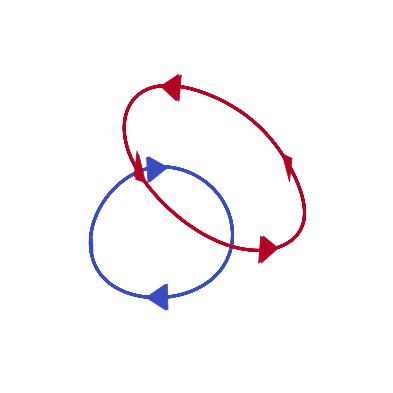

In [25]:
trnst = 50
with plotstyle.context("inputs", 2):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.grid(False)
    ax.axis('off')
    x = ks[:, 0, trnst:]
    y = ks[:, 1, trnst:]
    z = ks[:, 2, trnst:]
    xmin = x.min()
    ymin = y.min()
    zmin = z.min()
    ts = x.shape[1]

    for i in [0,-1]:
        line, = ax.plot(x[i,...],
                y[i,...],
                z[i,...]
        ) 
        
        arrow_times = np.linspace(0, ts / 2, 7).astype(int)
        dt = 3

        for t in arrow_times:

            if t + dt >= len(z[i,:]):
                continue

            dx = x[i,t + dt] - y[i,t]
            dy = y[i,t + dt] - y[i,t]
            dz = z[i,t + dt] - z[i,t]

            add_arrowhead_3d(
                ax,
                x[i,:],
                y[i,:],
                z[i,:],
                t,
                dt=dt,
                color = line.get_color(),
                head_length=0.1,
                head_width=0.04,
            )
#plt.savefig("Figures/Figures_3/og_basis.png")
plt.show()

In [27]:
compute_rate_similarity(rates, 0, 50)

[0.9999998, 0.29828006]

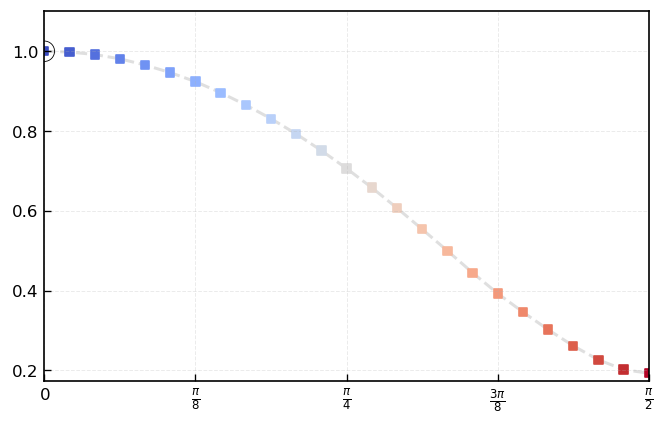

In [28]:
inputs = cycles.generate_inputs(NUM_ANGLES)
rates, _ = run_rnn(resampled, inputs)
with plotstyle.context("inputs", NUM_ANGLES):
    plot_traj_similarity(rates, 0, NUM_ANGLES)

# plt.savefig("../Figures/Figures_2/procrustes.png")
plt.show()
    

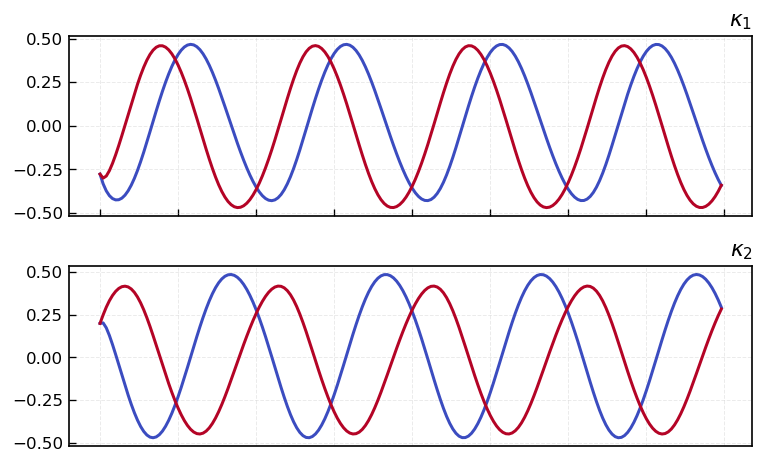

In [ ]:
with plotstyle.context("inputs", 2):
    fig, axs = plt.subplots(mf_model.rnn.rank,1, sharex=True)
    for i in [0,-1]:
        for j in range(mf_model.rnn.rank):
            axs[j].plot(mf_rates[i,:,j])
            axs[j].set_title(r"$\kappa_{0}$".format(j+1), loc="right")

    axs[mf_model.rnn.rank-1].tick_params(bottom=False, labelbottom=False)
    fig.tight_layout()
    
plt.show()

<class 'matplotlib.colors.LinearSegmentedColormap'>


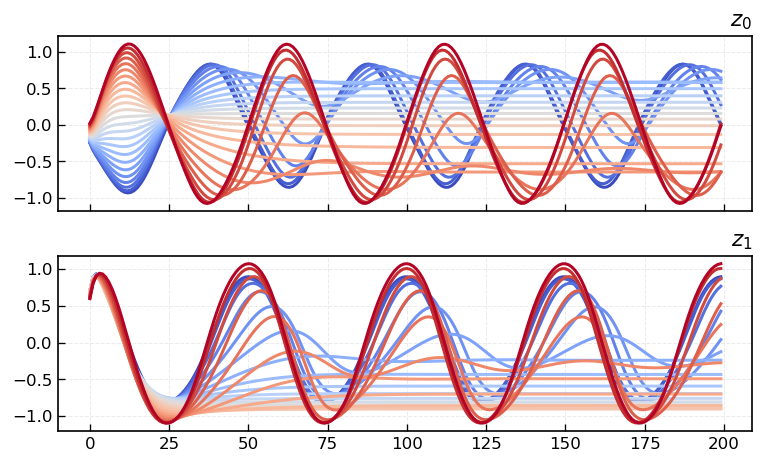

In [ ]:
with plotstyle.context("inputs", NUM_ANGLE):
    fig, axs = plt.subplots(mf_model.params["output_size"],1, sharex=True)
    for i in range(NUM_ANGLES):
        for j in range(mf_model.params["output_size"]):
            axs[j].plot(out[i,:,j])
            axs[j].set_title(r"$z_{0}$".format(j), loc="right")

    #axs[model.rnn.rank-1].tick_params(bottom=False, labelbottom=False)
    fig.tight_layout()

plt.show()

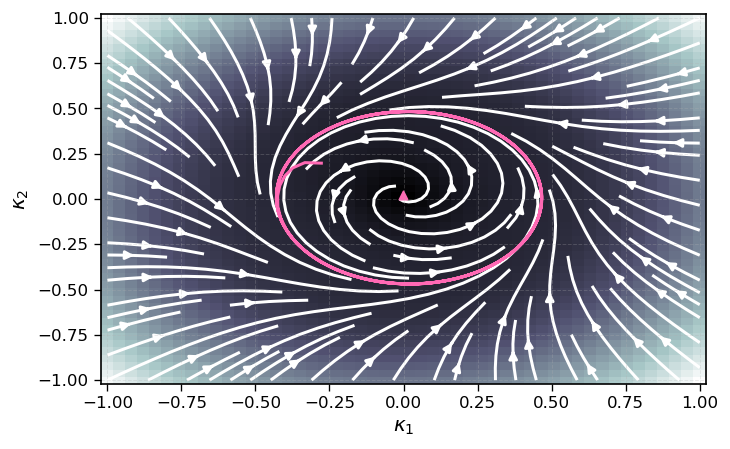

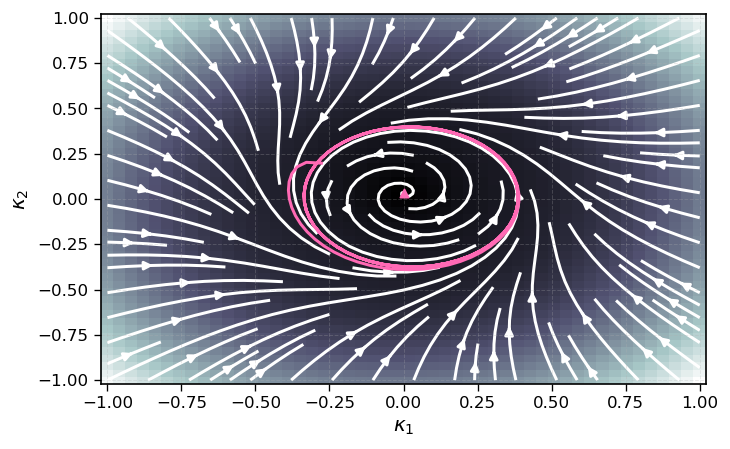

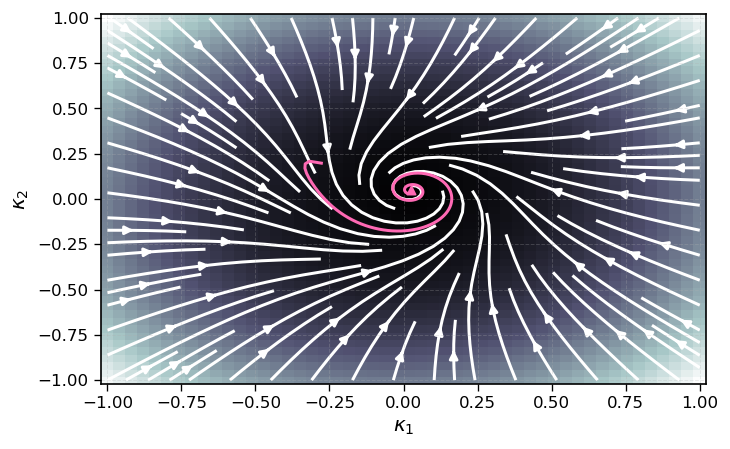

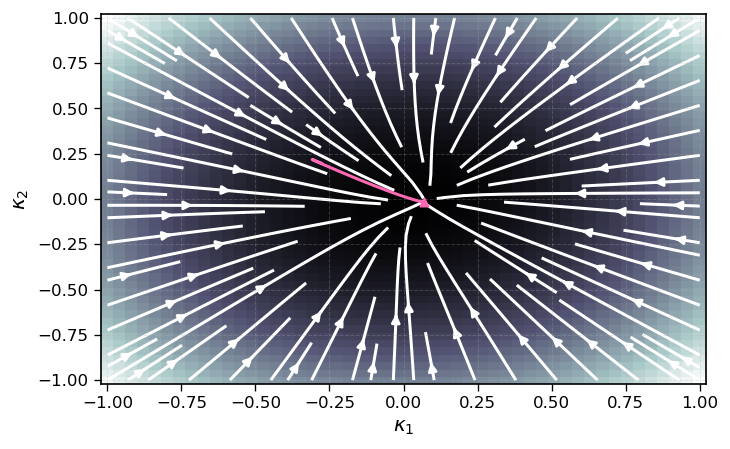

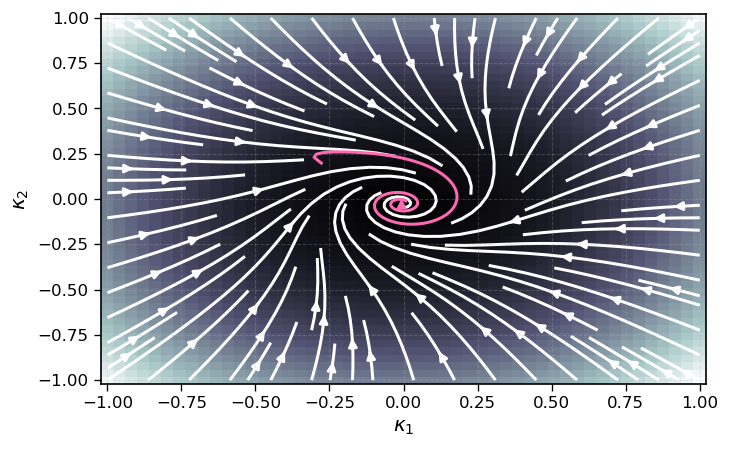

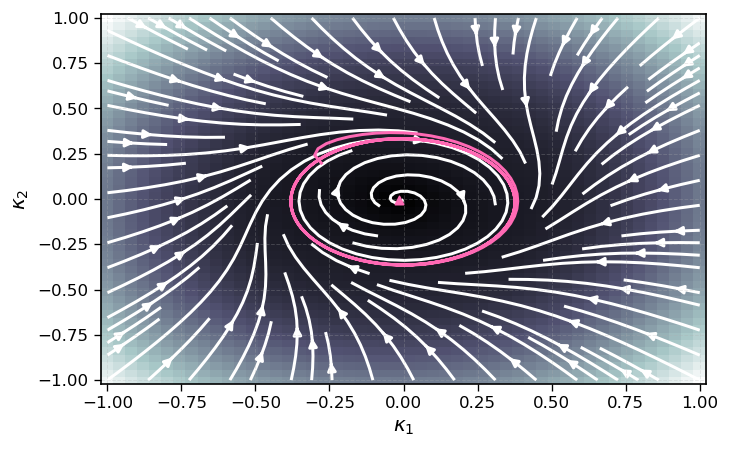

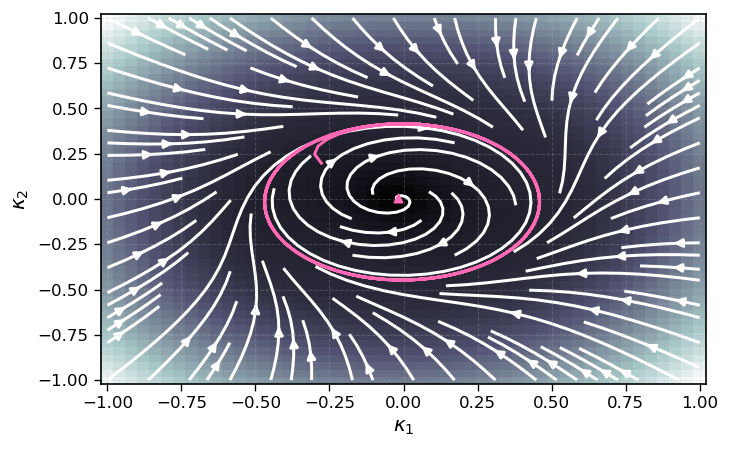

In [ ]:

idxs = np.linspace(0,NUM_ANGLES-1, 7, dtype=int)
for idx in idxs:
    plot_vector_field_MF(mf_model, inputs[idx,...].detach().numpy(), trnst=0, find_fps=True)
    # plt.savefig(f"../Figures/Figures_2/vectorffs_{idx}.png")
    plt.show()


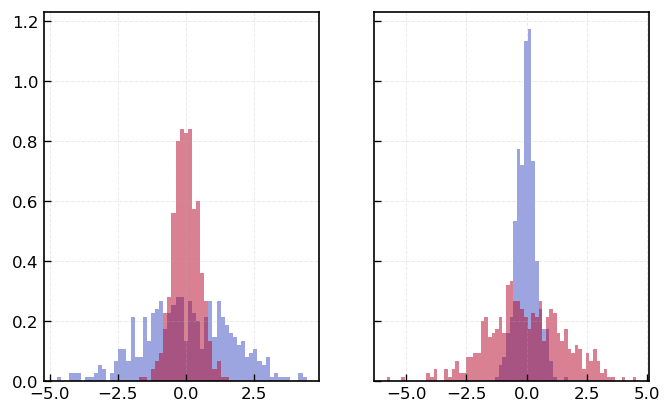

In [ ]:
import seaborn as sns
pops = np.zeros(1000, dtype=bool)
pops[500:] = 1
binwidth=.15

with plotstyle.context("inputs", 2):
    fig, axs = plt.subplots(1,2, sharey=True )
    w_in = model.rnn.w_in.detach().numpy()
    bins = np.arange(w_in[0,:].min(), w_in[0,:].max()+binwidth, binwidth)
    axs[0].hist(w_in[0,pops], alpha=.5, density=True, bins=bins)
    axs[0].hist(w_in[0,~pops], alpha=.5, density=True, bins=bins)

    bins = np.arange(w_in[1,:].min(), w_in[0,:].max()+binwidth, binwidth)
    axs[1].hist(w_in[1,pops], alpha=.5, density=True, bins=bins)
    axs[1].hist(w_in[1,~pops], alpha=.5, density=True, bins=bins)

# plt.savefig("../Figures/Figures_2/input_variances.png")    
plt.show()



In [ ]:
# LSA
fps, jacs = compute_fixed_point_simple(mf_model, inputs[0,0,:].detach().numpy())

reals = []
imags = [] 

for idx in range(NUM_ANGLES):

    fps, jacs = compute_fixed_point_simple(mf_model, inputs[idx,0,:].detach().numpy())
    eigs = [np.linalg.eig(jac) for jac in jacs]
    reals.append([np.real(l[0]) for l, _ in eigs])
    imags.append([np.imag(l[0]) for l, _ in eigs])

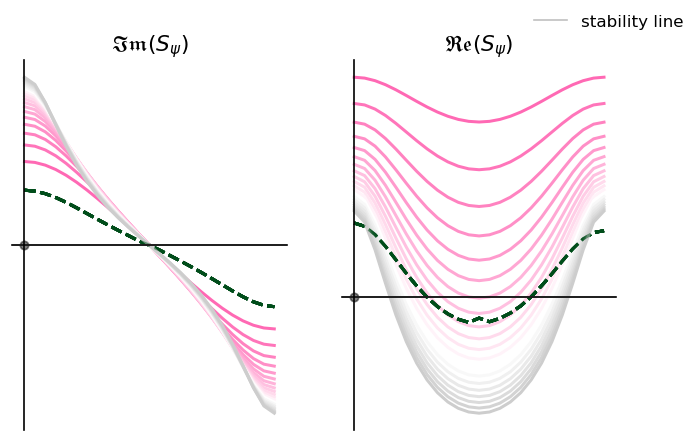

In [ ]:
#analytical: 
x = [r[0] for r in reals]
y = [imags[idx][0] if idx <= 12 else -imags[idx][0] for idx in range(len(imags))]
omega = 1.5
s_r = 1.0
sigmas = np.linspace(1,10, 20)
psis = np.linspace(0, np.pi/2, NUM_ANGLES)
g1s = [np.array([ 1 / np.sqrt(1 + np.pi/2 * np.cos(psi)**2 * sigma) for psi in psis]) for sigma in sigmas]
g2s = [np.array([ 1 / np.sqrt(1 + np.pi/2 * np.sin(psi)**2 * sigma) for psi in psis]) for sigma in sigmas]
fig = plt.figure()
ax = fig.add_subplot(121)
ax1 = fig.add_subplot(122)
center(ax)
center(ax1)

with plotstyle.context("general", NUM_ANGLES):
    for idx in range(len(g1s)):
        ax.plot(omega * (g2s[idx] - g1s[idx]))
        im1 = ax1.plot(-1 + s_r * (g2s[idx] + g1s[idx]))
        ax1.plot(x, c="#004d1a", alpha=.5, linestyle='--')
        ax.plot(y, c="#004d1a", alpha=.5, linestyle='--')
        ax.set_title(r"$\mathfrak{Im}(S_{\psi})$")
        ax1.set_title(r"$\mathfrak{Re}(S_{\psi})$")

    ax1.axhline(0, c="silver",alpha=1, linewidth=1, label="stability line")
    ax.axhline(0, c="silver", alpha=1, linewidth=1)
    fig.legend()
# plt.savefig("../Figures/Figures_2/bifurc.png")
plt.show()